In [1]:
# Length(독립변수 X) ──→ LinearRegression ──→ Weight(종속변수 y)
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# fish.csv 불러오기
url = "https://raw.githubusercontent.com/rickiepark/hg-mldl/master/fish.csv"
fish = pd.read_csv(url)

# Bream만 추출
bream = fish[fish["Species"] == "Bream"]

# 독립변수 X: Length
X = bream[["Length"]]

# 종속변수 y: Weight
y = bream["Weight"]

display(bream.head())

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.5200,4.0200
1,Bream,290.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,26.5,31.1,12.3778,4.6961
3,Bream,363.0,29.0,33.5,12.7300,4.4555
4,Bream,430.0,29.0,34.0,12.4440,5.1340


In [3]:
X = bream[["Length"]]   # DataFrame
y = bream["Weight"]     # Series


# 학습용 / 테스트용 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# 선형회귀 모델 학습
lr = LinearRegression()
lr.fit(X_train, y_train);


In [4]:
# Weight=기울기×Length+절편
print("기울기:", lr.coef_[0])
print("절편:", lr.intercept_)

기울기: 48.69324162692423
절편: -995.8353667592271


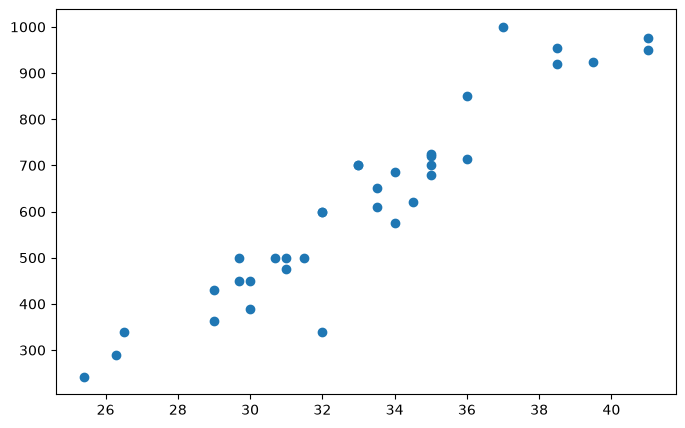

In [5]:
# 산점도 + 회귀 직선
plt.figure(figsize=(8, 5))

# 실제 Bream 데이터
plt.scatter(
    X,
    y,
    label="Bream"
)


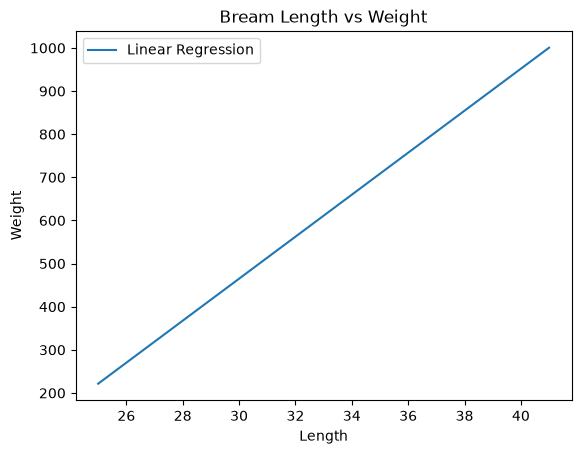

In [6]:
# 회귀 직선을 그리기 위한 X값
X_line = pd.DataFrame({
    "Length": range(int(X["Length"].min()), int(X["Length"].max()) + 1)
})

# 회귀 직선의 예측값
y_line = lr.predict(X_line)

# 회귀 직선
plt.plot(
    X_line["Length"],
    y_line,
    label="Linear Regression"
)

plt.xlabel("Length")
plt.ylabel("Weight")
plt.title("Bream Length vs Weight")
plt.legend()
plt.show()

In [7]:
# 예측
y_pred = lr.predict(X_test)
# 실제 데이터와 예측데이터 비교
display(pd.DataFrame({
    "실제 Weight": y_test,
    "예측 Weight": y_pred
}))

,실제 Weight,예측 Weight
26,720.0,708.428090
13,340.0,562.348365
24,700.0,708.428090
21,685.0,659.734849
15,600.0,562.348365
29,1000.0,805.814573
19,650.0,635.388228


In [10]:
# 모델 평가

# 훈련 데이터 결정계수
train_r2 = lr.score(X_train, y_train)

# 테스트 데이터 결정계수
test_r2 = lr.score(X_test, y_test)

print("훈련 데이터 결정계수(R²):", train_r2) # 0.9450143635974686
print("테스트 데이터 결정계수(R²):", test_r2) # 0.6047078779931725 -> 훈련데이터에 비해 너무 낮다 -> 과적합 의심 -> 반대이면 과소적합 의심

훈련 데이터 결정계수(R²): 0.9450143635974686
테스트 데이터 결정계수(R²): 0.6047078779931725


In [11]:
# 평가용 모듈을 이용하여 다른 평가지표도 출력 예)

from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

y_train_pred = lr.predict(X_train)
y_test_pred = lr.predict(X_test)

print("훈련 R²:", r2_score(y_train, y_train_pred))
print("테스트 R²:", r2_score(y_test, y_test_pred))


# R²
print("R²:", r2_score(y_test, y_test_pred))

# MAE
print("MAE:", mean_absolute_error(y_test, y_test_pred))

# MSE
print("MSE:", mean_squared_error(y_test, y_test_pred))

# RMSE
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))
# LinearRegression.score(X, y)는 회귀에서는 R²를 반환하지만,
# 분류 모델의 .score()는 일반적으로 Accuracy를 반환한다.

훈련 R²: 0.9450143635974686
테스트 R²: 0.6047078779931725
R²: 0.6047078779931725
MAE: 73.4374786091571
MSE: 12803.027800631337
RMSE: 113.15046531336641


In [ ]:
# 모델들은 결정계수, 정확도(Accuracy), 외에도 여러 평가 지표를 사용한다. 각각의 항목에 대해서는 뒤에서 설명한다.

# 회귀
#  ├─ R²    → 1에 가까울수록 좋음, 클수록 좋음
#  ├─ MAE(실제값과 예측값 차이의 절댓값 평균)    → 0에 가까울수록 좋음, 작을수록 좋음
#  ├─ MSE(오차를 제곱한 값의 평균)    → 0에 가까울수록 좋음, 작을수록 좋음
#  ├─ RMSE(MSE에 제곱근을 적용)   → 0에 가까울수록 좋음, 작을수록 좋음
#  └─ MAPE(실제값 대비 오차의 비율 평균)   → 0%에 가까울수록 좋음, 작을수록 좋음

# 분류
#  | 평가 지표     | 설명
#  | ------------- | ----------------------------------------------------------
#  | **Accuracy**  | 전체 중 **맞게 예측한 비율**          높을수록 좋음
#  | **Precision** | **양성이라고 예측한 것 중** 실제 양성 비율  높을수록 좋음
#  | **Recall**    | **실제 양성 중** 양성으로 찾아낸 비율    높을수록 좋음
#  | **F1-score**  | Precision과 Recall의 **균형**   높을수록 좋음
#  | **ROC-AUC**   | 양성과 음성을 **얼마나 잘 구분하는지**     높을수록 좋음